Đã lưu: model_comparison_metrics.png


C:\Users\T14\AppData\Local\Temp\ipykernel_20488\3102888457.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp, x='Importance', y='Feature', ax=ax, palette='mako')


Đã lưu: feature_importance_best_model.png
Đã lưu: actual_vs_predicted.png


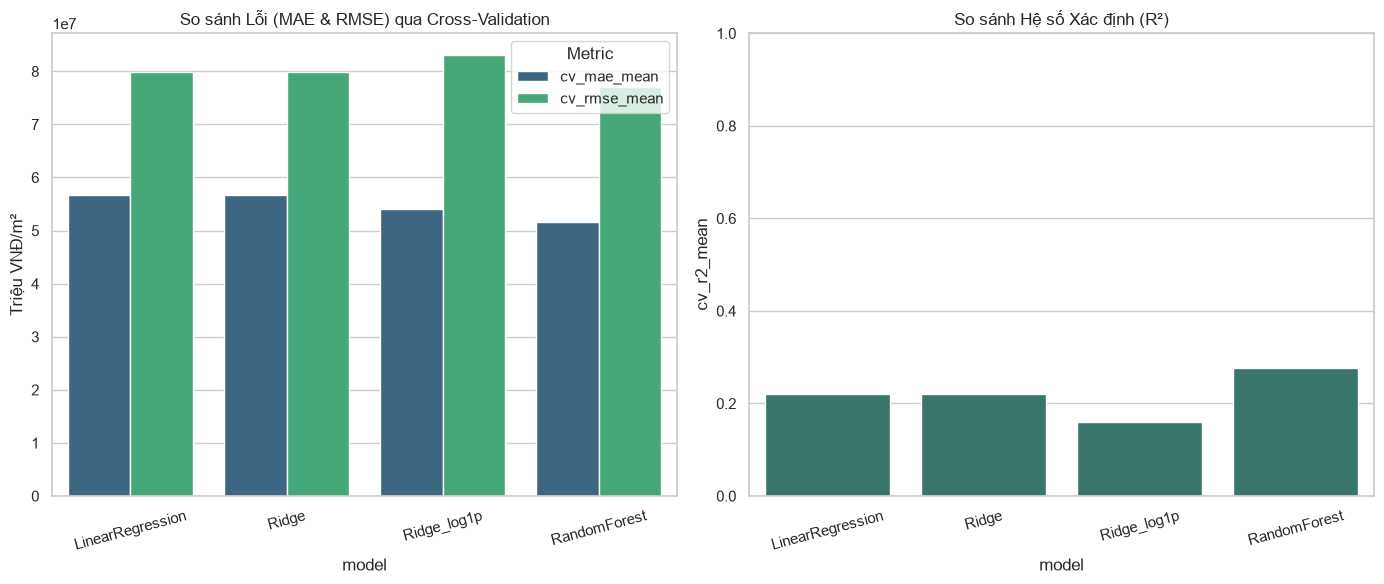

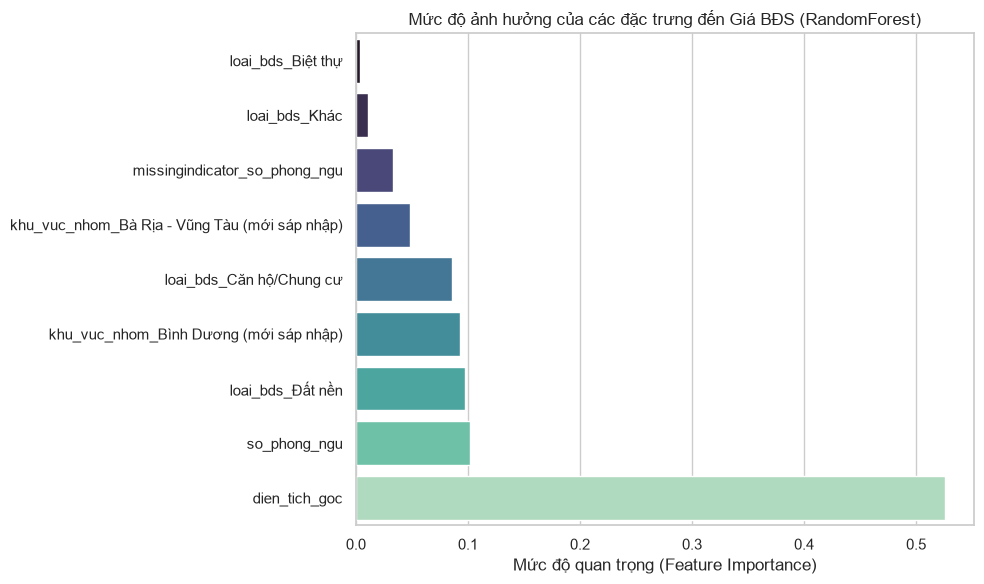

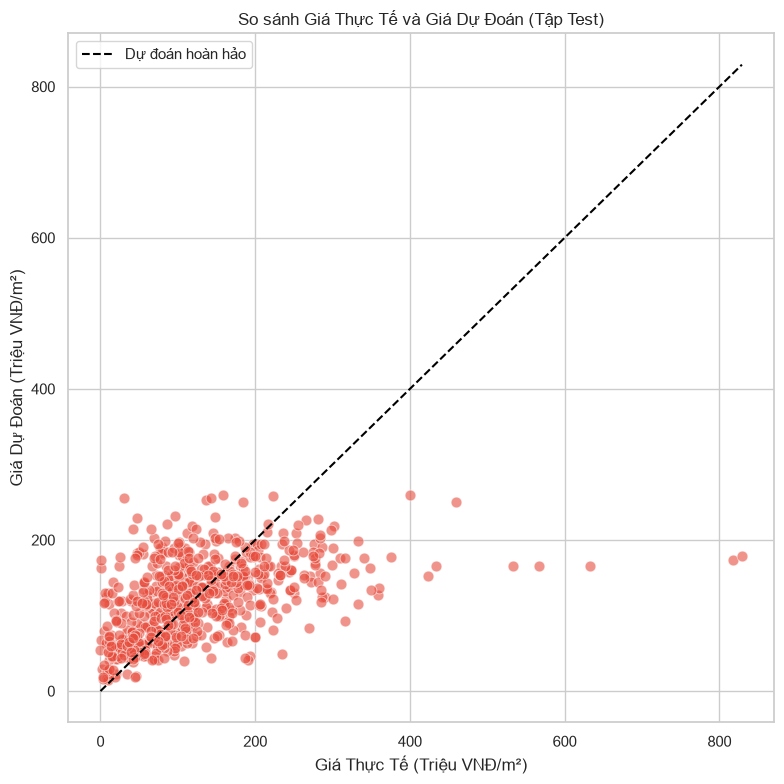

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

REPORTS_DIR = Path('reports')
FIGURES_DIR = REPORTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12, 'figure.titlesize': 16})


def plot_model_comparison():
    df_comp = pd.read_csv(REPORTS_DIR / 'model_comparison.csv')
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    df_melt_error = df_comp.melt(id_vars='model', value_vars=['cv_mae_mean', 'cv_rmse_mean'], 
                                 var_name='Metric', value_name='Error (VNĐ/m2)')
    sns.barplot(data=df_melt_error, x='model', y='Error (VNĐ/m2)', hue='Metric', ax=axes[0], palette='viridis')
    axes[0].set_title('So sánh Lỗi (MAE & RMSE) qua Cross-Validation')
    axes[0].set_ylabel('Triệu VNĐ/m²')
    axes[0].tick_params(axis='x', rotation=15)
    
    sns.barplot(data=df_comp, x='model', y='cv_r2_mean', ax=axes[1], color='#2f7f72')
    axes[1].set_title('So sánh Hệ số Xác định (R²)')
    axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis='x', rotation=15)
    
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / 'model_comparison_metrics.png', dpi=160, bbox_inches='tight')
    print("Đã lưu: model_comparison_metrics.png")


def plot_feature_importance():
    model_pipeline = joblib.load('models/best_model.joblib')
    
    rf_model = model_pipeline.named_steps['model']
    preprocessor = model_pipeline.named_steps['preprocess']
    
    feature_names = preprocessor.get_feature_names_out()
    importances = rf_model.feature_importances_
    
    df_imp = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values('Importance', ascending=True) 
    
    df_imp['Feature'] = df_imp['Feature'].str.replace('num__', '').str.replace('cat__', '')
    
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=df_imp, x='Importance', y='Feature', ax=ax, palette='mako')
    ax.set_title('Mức độ ảnh hưởng của các đặc trưng đến Giá BĐS (RandomForest)')
    ax.set_xlabel('Mức độ quan trọng (Feature Importance)')
    ax.set_ylabel('')
    
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / 'feature_importance_best_model.png', dpi=160, bbox_inches='tight')
    print("Đã lưu: feature_importance_best_model.png")


def plot_actual_vs_predicted_static():
    model_pipeline = joblib.load('models/best_model.joblib')
    df_test = pd.read_csv('data/processed/model_test_raw.csv')
    
    X_test = df_test[['dien_tich_goc', 'so_phong_ngu', 'khu_vuc_nhom', 'loai_bds']]
    y_test_actual = df_test['price_per_m2'] / 1_000_000 
    y_test_pred = model_pipeline.predict(X_test) / 1_000_000
    
    fig, ax = plt.subplots(figsize=(8, 8))
    sns.scatterplot(x=y_test_actual, y=y_test_pred, alpha=0.6, color='#e74c3c', edgecolor='w', s=60, ax=ax)
    
    max_val = max(y_test_actual.max(), y_test_pred.max())
    ax.plot([0, max_val], [0, max_val], color='black', linestyle='--', linewidth=1.5, label='Dự đoán hoàn hảo')
    
    ax.set_title('So sánh Giá Thực Tế và Giá Dự Đoán (Tập Test)')
    ax.set_xlabel('Giá Thực Tế (Triệu VNĐ/m²)')
    ax.set_ylabel('Giá Dự Đoán (Triệu VNĐ/m²)')
    ax.legend()
    
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / 'actual_vs_predicted.png', dpi=160, bbox_inches='tight')
    print("Đã lưu: actual_vs_predicted.png")

plot_model_comparison()
plot_feature_importance()
plot_actual_vs_predicted_static()